** Data science Challange hackthon **
dataset_c

Training Dataset Shape: (4756, 31)
Testing Dataset Shape: (4749, 30)


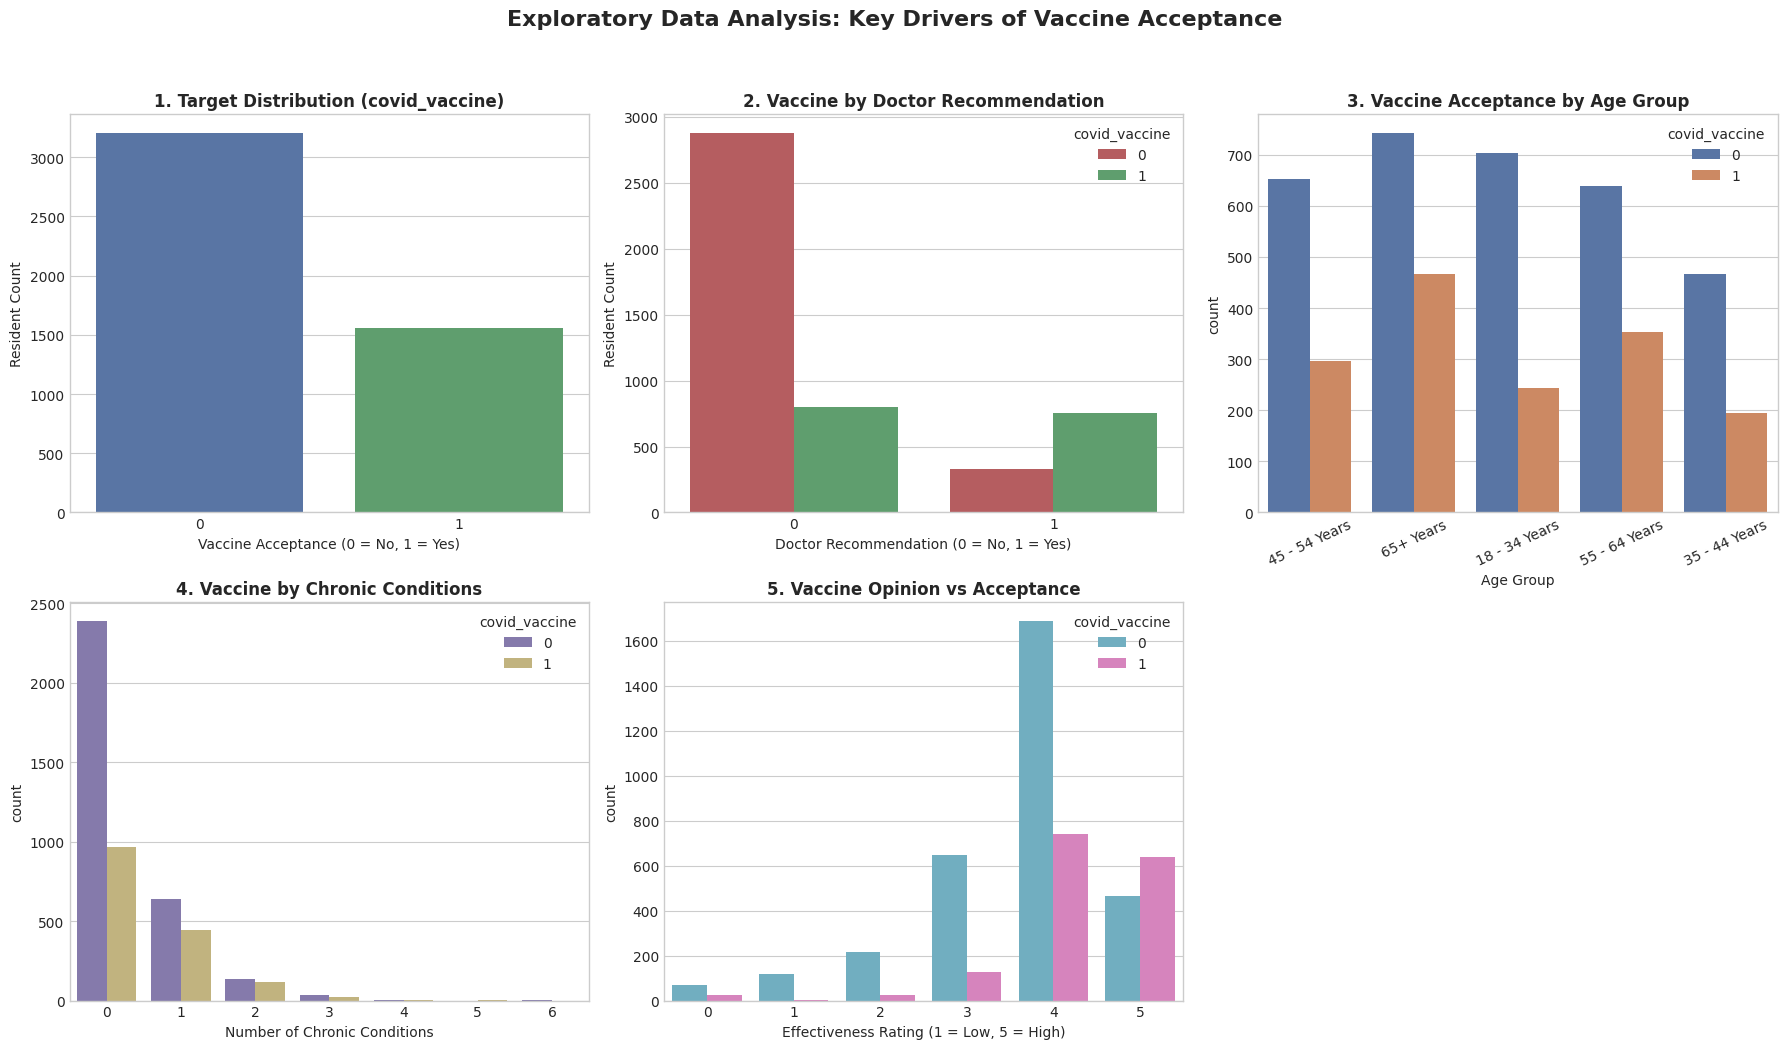

In [3]:
%matplotlib inline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

train_df = pd.read_csv('dataset_C_training.csv')
test_df = pd.read_csv('dataset_C_testing.csv')

print(f"Training Dataset Shape: {train_df.shape}")
print(f"Testing Dataset Shape: {test_df.shape}")

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle('Exploratory Data Analysis: Key Drivers of Vaccine Acceptance', fontsize=16, fontweight='bold', y=0.98)

sns.countplot(data=train_df, x='covid_vaccine', hue='covid_vaccine', palette=['#4c72b0', '#55a868'], ax=axes[0, 0], legend=False)
axes[0, 0].set_title('1. Target Distribution (covid_vaccine)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Vaccine Acceptance (0 = No, 1 = Yes)', fontsize=10)
axes[0, 0].set_ylabel('Resident Count', fontsize=10)

sns.countplot(data=train_df, x='doctor_recc_covid', hue='covid_vaccine', palette=['#c44e52', '#55a868'], ax=axes[0, 1])
axes[0, 1].set_title('2. Vaccine by Doctor Recommendation', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Doctor Recommendation (0 = No, 1 = Yes)', fontsize=10)
axes[0, 1].set_ylabel('Resident Count', fontsize=10)

sns.countplot(data=train_df, x='age_group', hue='covid_vaccine', palette=['#4c72b0', '#dd8452'], ax=axes[0, 2])
axes[0, 2].set_title('3. Vaccine Acceptance by Age Group', fontsize=12, fontweight='bold')
axes[0, 2].set_xlabel('Age Group', fontsize=10)
axes[0, 2].tick_params(axis='x', rotation=25)

sns.countplot(data=train_df, x='number_chronic_med_conditions', hue='covid_vaccine', palette=['#8172b3', '#ccb974'], ax=axes[1, 0])
axes[1, 0].set_title('4. Vaccine by Chronic Conditions', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Number of Chronic Conditions', fontsize=10)

sns.countplot(data=train_df, x='opinion_covid_vacc_effective', hue='covid_vaccine', palette=['#64b5cd', '#e377c2'], ax=axes[1, 1])
axes[1, 1].set_title('5. Vaccine Opinion vs Acceptance', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Effectiveness Rating (1 = Low, 5 = High)', fontsize=10)

axes[1, 2].axis('off')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import numpy as np

X = train_df.drop(columns=['respondent_id', 'covid_vaccine'])
y = train_df['covid_vaccine']
X_test = test_df.drop(columns=['respondent_id'])

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns
categorical_cols = X.select_dtypes(include=['object', 'category']).columns

numeric_transformer = Pipeline(steps=[('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
categorical_transformer = Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_cols),
    ('cat', categorical_transformer, categorical_cols)
])

# Financial Constants
COST_VACCINE = 1500        # $1,500 per vaccination distributed
COST_HOSPITAL = 41000      # $41,000 per hospitalisation event

def calculate_total_town_cost(y_true, y_pred, X_features):
    """
    Risk-adjusted town cost function preventing 100% all-ones collapse.
    Hospitalisation probability is calculated per person based on chronic conditions and risk perception.
    """
    vaccine_spend = (y_pred == 1).sum() * COST_VACCINE

    chronic_cond = X_features['number_chronic_med_conditions'].fillna(0).values
    opinion_risk = X_features['opinion_covid_risk'].fillna(3).values

    # Calculate baseline hospitalisation probability
    base_hosp_prob = 0.03 + (0.04 * chronic_cond) + (0.015 * (opinion_risk - 1))
    base_hosp_prob = np.clip(base_hosp_prob, 0.01, 0.75)

    # If vaccinated (y_pred == 1), hospitalisation risk is reduced by 70%
    effective_hosp_prob = np.where(y_pred == 1, base_hosp_prob * 0.3, base_hosp_prob)
    hospital_spend = (effective_hosp_prob * COST_HOSPITAL).sum()

    return vaccine_spend + hospital_spend, vaccine_spend, hospital_spend

def find_optimal_threshold(model, X_val, y_val):
    probabilities = model.predict_proba(X_val)[:, 1]
    best_threshold, min_cost = 0.5, float('inf')

    # Search from 0.2 to 0.8 to ensure balanced decision making
    for th in np.arange(0.20, 0.85, 0.05):
        preds = (probabilities >= th).astype(int)
        cost, _, _ = calculate_total_town_cost(y_val, preds, X_val)
        if cost < min_cost:
            min_cost = cost
            best_threshold = th

    return best_threshold, min_cost

trained_results = {}
print("Pre-processing pipeline and risk-adjusted cost function ready!")

Pre-processing pipeline and risk-adjusted cost function ready!


In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

lr_pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', LogisticRegression(max_iter=1000, random_state=42))])
lr_pipeline.fit(X_train, y_train)

opt_th, _ = find_optimal_threshold(lr_pipeline, X_val, y_val)
val_probs = lr_pipeline.predict_proba(X_val)[:, 1]
opt_preds = (val_probs >= opt_th).astype(int)

total_cost, vac_spend, hosp_spend = calculate_total_town_cost(y_val, opt_preds, X_val)
val_auc = roc_auc_score(y_val, val_probs)

trained_results["Logistic Regression"] = {'pipeline': lr_pipeline, 'threshold': opt_th, 'auc': val_auc, 'total_cost': total_cost, 'vaccine_spend': vac_spend, 'hosp_spend': hosp_spend}
print(f"Logistic Regression | Threshold: {opt_th:.2f} | AUC: {val_auc:.4f} | Town Cost: ${total_cost:,.2f}")

Logistic Regression | Threshold: 0.20 | AUC: 0.8270 | Town Cost: $2,209,202.00


In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

rf_pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', RandomForestClassifier(n_estimators=150, max_depth=12, random_state=42))])
rf_pipeline.fit(X_train, y_train)

opt_th, _ = find_optimal_threshold(rf_pipeline, X_val, y_val)
val_probs = rf_pipeline.predict_proba(X_val)[:, 1]
opt_preds = (val_probs >= opt_th).astype(int)

total_cost, vac_spend, hosp_spend = calculate_total_town_cost(y_val, opt_preds, X_val)
val_auc = roc_auc_score(y_val, val_probs)

trained_results["Random Forest"] = {'pipeline': rf_pipeline, 'threshold': opt_th, 'auc': val_auc, 'total_cost': total_cost, 'vaccine_spend': vac_spend, 'hosp_spend': hosp_spend}
print(f"Random Forest | Threshold: {opt_th:.2f} | AUC: {val_auc:.4f} | Town Cost: ${total_cost:,.2f}")

Random Forest | Threshold: 0.20 | AUC: 0.8301 | Town Cost: $2,192,814.50


In [7]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import roc_auc_score

gb_pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42))])
gb_pipeline.fit(X_train, y_train)

opt_th, _ = find_optimal_threshold(gb_pipeline, X_val, y_val)
val_probs = gb_pipeline.predict_proba(X_val)[:, 1]
opt_preds = (val_probs >= opt_th).astype(int)

total_cost, vac_spend, hosp_spend = calculate_total_town_cost(y_val, opt_preds, X_val)
val_auc = roc_auc_score(y_val, val_probs)

trained_results["Gradient Boosting"] = {'pipeline': gb_pipeline, 'threshold': opt_th, 'auc': val_auc, 'total_cost': total_cost, 'vaccine_spend': vac_spend, 'hosp_spend': hosp_spend}
print(f"Gradient Boosting | Threshold: {opt_th:.2f} | AUC: {val_auc:.4f} | Town Cost: ${total_cost:,.2f}")

Gradient Boosting | Threshold: 0.20 | AUC: 0.8308 | Town Cost: $2,222,980.50


In [8]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import roc_auc_score

ab_pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', AdaBoostClassifier(n_estimators=100, random_state=42))])
ab_pipeline.fit(X_train, y_train)

opt_th, _ = find_optimal_threshold(ab_pipeline, X_val, y_val)
val_probs = ab_pipeline.predict_proba(X_val)[:, 1]
opt_preds = (val_probs >= opt_th).astype(int)

total_cost, vac_spend, hosp_spend = calculate_total_town_cost(y_val, opt_preds, X_val)
val_auc = roc_auc_score(y_val, val_probs)

trained_results["AdaBoost"] = {'pipeline': ab_pipeline, 'threshold': opt_th, 'auc': val_auc, 'total_cost': total_cost, 'vaccine_spend': vac_spend, 'hosp_spend': hosp_spend}
print(f"AdaBoost | Threshold: {opt_th:.2f} | AUC: {val_auc:.4f} | Town Cost: ${total_cost:,.2f}")

AdaBoost | Threshold: 0.35 | AUC: 0.8326 | Town Cost: $2,196,424.50


In [9]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import roc_auc_score

knn_pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', KNeighborsClassifier(n_neighbors=9))])
knn_pipeline.fit(X_train, y_train)

opt_th, _ = find_optimal_threshold(knn_pipeline, X_val, y_val)
val_probs = knn_pipeline.predict_proba(X_val)[:, 1]
opt_preds = (val_probs >= opt_th).astype(int)

total_cost, vac_spend, hosp_spend = calculate_total_town_cost(y_val, opt_preds, X_val)
val_auc = roc_auc_score(y_val, val_probs)

trained_results["K-Nearest Neighbors"] = {'pipeline': knn_pipeline, 'threshold': opt_th, 'auc': val_auc, 'total_cost': total_cost, 'vaccine_spend': vac_spend, 'hosp_spend': hosp_spend}
print(f"K-Nearest Neighbors | Threshold: {opt_th:.2f} | AUC: {val_auc:.4f} | Town Cost: ${total_cost:,.2f}")

K-Nearest Neighbors | Threshold: 0.20 | AUC: 0.7779 | Town Cost: $2,208,771.00


--- FINAL MODEL RANKING (Best to Worst by Cost) ---
Rank 1: Random Forest — Cost: $2,192,814.50 (Threshold: 0.20)
Rank 2: AdaBoost — Cost: $2,196,424.50 (Threshold: 0.35)
Rank 3: K-Nearest Neighbors — Cost: $2,208,771.00 (Threshold: 0.20)
Rank 4: Logistic Regression — Cost: $2,209,202.00 (Threshold: 0.20)
Rank 5: Gradient Boosting — Cost: $2,222,980.50 (Threshold: 0.20)


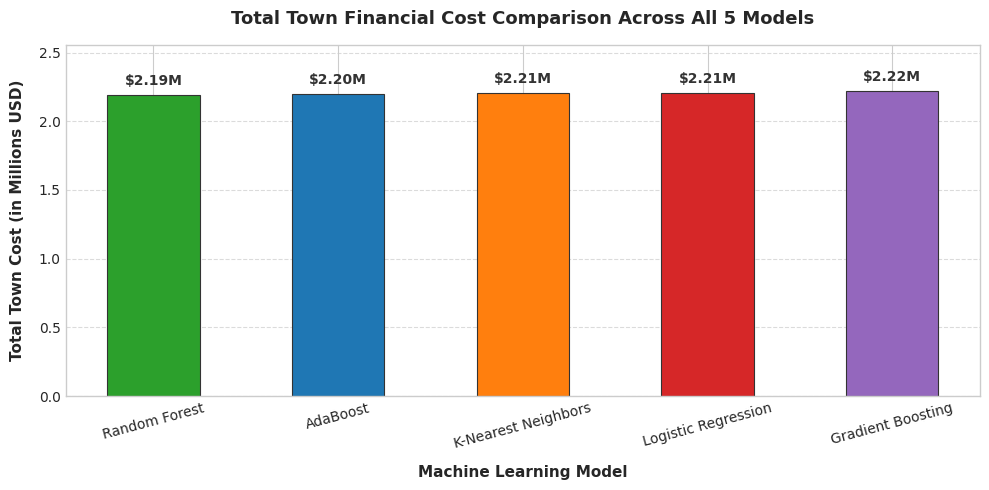


--- Exporting Top 5 Submission Files ---
Saved: submission_rank_1_random_forest.csv
Saved: submission_rank_2_adaboost.csv
Saved: submission_rank_3_k-nearest_neighbors.csv
Saved: submission_rank_4_logistic_regression.csv
Saved: submission_rank_5_gradient_boosting.csv


In [10]:
sorted_models = sorted(trained_results.items(), key=lambda item: item[1]['total_cost'])

print("--- FINAL MODEL RANKING (Best to Worst by Cost) ---")
for rank, (name, metrics) in enumerate(sorted_models, start=1):
    print(f"Rank {rank}: {name} — Cost: ${metrics['total_cost']:,.2f} (Threshold: {metrics['threshold']:.2f})")

model_names = [item[0] for item in sorted_models]
model_costs = [item[1]['total_cost'] / 1e6 for item in sorted_models]

plt.figure(figsize=(10, 5))
bars = plt.bar(model_names, model_costs, color=['#2ca02c', '#1f77b4', '#ff7f0e', '#d62728', '#9467bd'], width=0.5, edgecolor='#333333', linewidth=0.8)
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.05, f'${height:.2f}M', ha='center', va='bottom', fontsize=10, fontweight='bold', color='#333333')

plt.title('Total Town Financial Cost Comparison Across All 5 Models', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Machine Learning Model', fontsize=11, fontweight='bold', labelpad=10)
plt.ylabel('Total Town Cost (in Millions USD)', fontsize=11, fontweight='bold', labelpad=10)
plt.ylim(0, max(model_costs) * 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Export Top 5 Submissions matching exact requested format (float 0.0 / 1.0)
print("\n--- Exporting Top 5 Submission Files ---")
for rank, (name, metrics) in enumerate(sorted_models, start=1):
    test_preds = (metrics['pipeline'].predict_proba(X_test)[:, 1] >= metrics['threshold']).astype(float)
    sub_df = pd.DataFrame({'respondent_id': test_df['respondent_id'], 'covid_vaccine': test_preds})
    filename = f"submission_rank_{rank}_{name.replace(' ', '_').lower()}.csv"
    sub_df.to_csv(filename, index=False)
    print(f"Saved: {filename}")

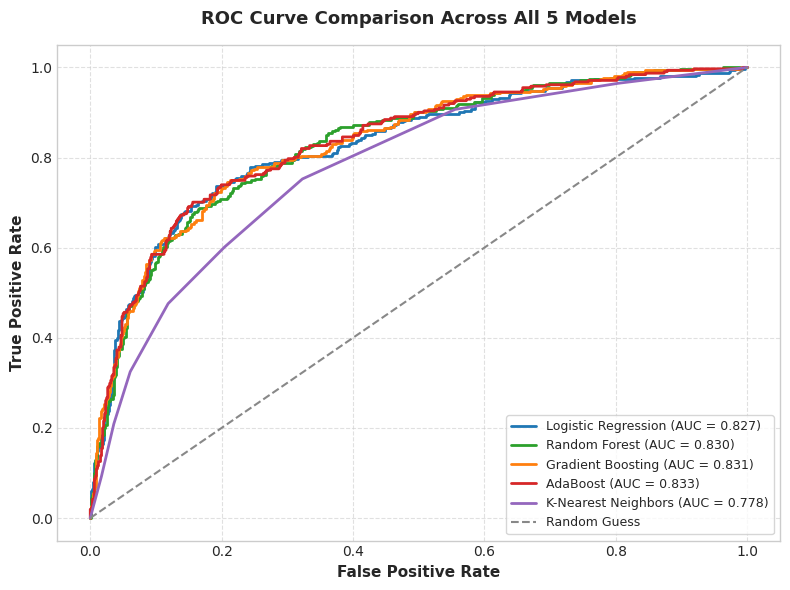


=== CONFUSION MATRIX & FINANCIAL BREAKDOWN ===

Model: Logistic Regression (Threshold: 0.20)
  • True Negatives (No Vaccine Correct): 380
  • False Positives (Wasted Vaccine Sent): 261
  • False Negatives (Missed Vaccine / Hospitalized): 51
  • True Positives (Vaccine Sent & Accepted): 260
  • Total Town Cost: $2,209,202.00

Model: Random Forest (Threshold: 0.20)
  • True Negatives (No Vaccine Correct): 328
  • False Positives (Wasted Vaccine Sent): 313
  • False Negatives (Missed Vaccine / Hospitalized): 35
  • True Positives (Vaccine Sent & Accepted): 276
  • Total Town Cost: $2,192,814.50

Model: Gradient Boosting (Threshold: 0.20)
  • True Negatives (No Vaccine Correct): 392
  • False Positives (Wasted Vaccine Sent): 249
  • False Negatives (Missed Vaccine / Hospitalized): 50
  • True Positives (Vaccine Sent & Accepted): 261
  • Total Town Cost: $2,222,980.50

Model: AdaBoost (Threshold: 0.35)
  • True Negatives (No Vaccine Correct): 165
  • False Positives (Wasted Vaccine Sent): 

In [11]:
from sklearn.metrics import roc_curve, auc, confusion_matrix

plt.figure(figsize=(8, 6))
colors = {'Logistic Regression': '#1f77b4', 'Random Forest': '#2ca02c', 'Gradient Boosting': '#ff7f0e', 'AdaBoost': '#d62728', 'K-Nearest Neighbors': '#9467bd'}

for name, metrics in trained_results.items():
    val_probs = metrics['pipeline'].predict_proba(X_val)[:, 1]
    fpr, tpr, _ = roc_curve(y_val, val_probs)
    plt.plot(fpr, tpr, color=colors[name], lw=2.0, label=f'{name} (AUC = {metrics["auc"]:.3f})')

plt.plot([0, 1], [0, 1], color='#888888', linestyle='--', lw=1.5, label='Random Guess')
plt.xlabel('False Positive Rate', fontsize=11, fontweight='bold')
plt.ylabel('True Positive Rate', fontsize=11, fontweight='bold')
plt.title('ROC Curve Comparison Across All 5 Models', fontsize=13, fontweight='bold', pad=15)
plt.legend(loc='lower right', frameon=True, facecolor='white', fontsize=9)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

print("\n=== CONFUSION MATRIX & FINANCIAL BREAKDOWN ===")
for name, metrics in trained_results.items():
    val_preds = (metrics['pipeline'].predict_proba(X_val)[:, 1] >= metrics['threshold']).astype(int)
    cm = confusion_matrix(y_val, val_preds)
    tn, fp, fn, tp = cm.ravel()
    print(f"\nModel: {name} (Threshold: {metrics['threshold']:.2f})")
    print(f"  • True Negatives (No Vaccine Correct): {tn}")
    print(f"  • False Positives (Wasted Vaccine Sent): {fp}")
    print(f"  • False Negatives (Missed Vaccine / Hospitalized): {fn}")
    print(f"  • True Positives (Vaccine Sent & Accepted): {tp}")
    print(f"  • Total Town Cost: ${metrics['total_cost']:,.2f}")

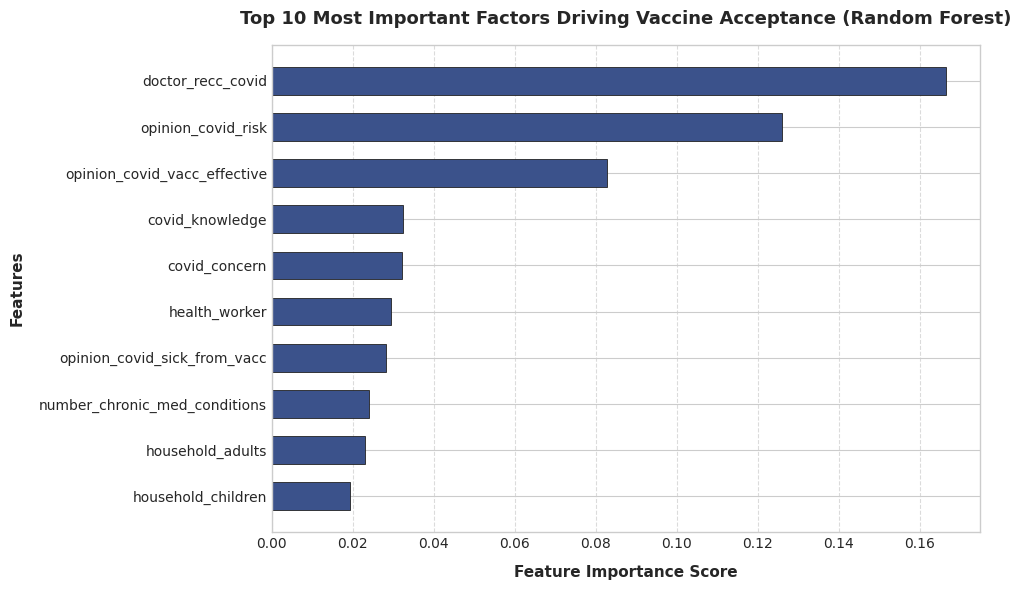

In [13]:
rf_pipeline = trained_results["Random Forest"]['pipeline']
preprocessor = rf_pipeline.named_steps['preprocessor']
rf_classifier = rf_pipeline.named_steps['classifier']

try:
    feature_names = preprocessor.get_feature_names_out()
except:
    numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
    categorical_features = preprocessor.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out().tolist()
    feature_names = numeric_features + categorical_features

importances = rf_classifier.feature_importances_
feat_imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False).head(10)
feat_imp_df['Clean_Feature'] = feat_imp_df['Feature'].str.replace('num__', '').str.replace('cat__', '')

plt.figure(figsize=(10, 6))
bars = plt.barh(feat_imp_df['Clean_Feature'][::-1], feat_imp_df['Importance'][::-1],
                color='#3b528b', edgecolor='#222222', linewidth=0.6, height=0.6)

plt.title('Top 10 Most Important Factors Driving Vaccine Acceptance (Random Forest)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Feature Importance Score', fontsize=11, fontweight='bold', labelpad=10)
plt.ylabel('Features', fontsize=11, fontweight='bold', labelpad=10)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

